In [64]:
# Importing Libraries
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt  

# Loading Data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data Cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

In [65]:
#create a copy of our data frame
df_US = df[df['job_country']=='United States'].copy()

In [66]:
#create a new column of month
df_US['job_posted_month']= df_US['job_posted_date'].dt.strftime('%B')

In [67]:
df_US_pivot = df_US.pivot_table(index = 'job_posted_month', columns = 'job_title_short', aggfunc = 'size')
df_US_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
April,565,40,6049,2801,4867,51,1025,781,991,112
August,903,39,6634,3269,6318,68,1186,903,1515,194
December,648,40,3979,2641,3472,119,601,689,752,212
February,447,24,6124,3060,4956,56,1258,878,1127,90
January,527,36,8494,2655,6915,60,1544,773,1552,114
July,581,39,5201,2570,4876,65,883,747,1095,153
June,446,32,5683,2893,4645,48,1009,812,1033,93
March,438,19,6218,3183,4779,59,1114,829,1150,115
May,279,20,4993,2976,4377,49,839,746,914,90


In [68]:
df_US_pivot = df_US_pivot.reset_index()
df_US_pivot['month num'] = pd.to_datetime(df_US_pivot['job_posted_month'], format='%B').dt.month
df_US_pivot = df_US_pivot.sort_values('month num')
df_US_pivot = df_US_pivot.set_index('job_posted_month')
df_US_pivot = df_US_pivot.drop(columns='month num')
df_US_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114
February,447,24,6124,3060,4956,56,1258,878,1127,90
March,438,19,6218,3183,4779,59,1114,829,1150,115
April,565,40,6049,2801,4867,51,1025,781,991,112
May,279,20,4993,2976,4377,49,839,746,914,90
June,446,32,5683,2893,4645,48,1009,812,1033,93
July,581,39,5201,2570,4876,65,883,747,1095,153
August,903,39,6634,3269,6318,68,1186,903,1515,194
September,897,50,4639,3224,4568,113,805,775,1014,228


In [69]:
df_US_software_pivot = pd.read_csv('https://lukeb.co/software_csv', index_col='job_posted_month')

df_US_software_pivot

,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,
January,13619,9827,5108,4348
February,11456,9116,7298,4284
March,11102,8178,5814,4159
April,14037,9209,7232,4220
May,12126,8864,6718,4980
June,12003,8065,5902,4781
July,11914,8061,6839,4344
August,11571,8191,7413,4104
September,14016,8447,6139,4094


In [70]:
#merge Data frame
df_US_merged = df_US_pivot.merge(df_US_software_pivot, on = 'job_posted_month')
df_US_merged

,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer,Front-End Developer,Back-End Developer,Full-Stack Developer,UI/UX Designer
job_posted_month,,,,,,,,,,,,,,
January,527,36,8494,2655,6915,60,1544,773,1552,114,13619,9827,5108,4348
February,447,24,6124,3060,4956,56,1258,878,1127,90,11456,9116,7298,4284
March,438,19,6218,3183,4779,59,1114,829,1150,115,11102,8178,5814,4159
April,565,40,6049,2801,4867,51,1025,781,991,112,14037,9209,7232,4220
May,279,20,4993,2976,4377,49,839,746,914,90,12126,8864,6718,4980
June,446,32,5683,2893,4645,48,1009,812,1033,93,12003,8065,5902,4781
July,581,39,5201,2570,4876,65,883,747,1095,153,11914,8061,6839,4344
August,903,39,6634,3269,6318,68,1186,903,1515,194,11571,8191,7413,4104
September,897,50,4639,3224,4568,113,805,775,1014,228,14016,8447,6139,4094


In [71]:
# find top 5 job titles (columns) in df_US_merged
top_5 = df_US_merged.sum().sort_values(ascending = False).head().index
top_5  = top_5.tolist()
top_5

['Front-End Developer',
 'Back-End Developer',
 'Full-Stack Developer',
 'Data Analyst',
 'Data Scientist']

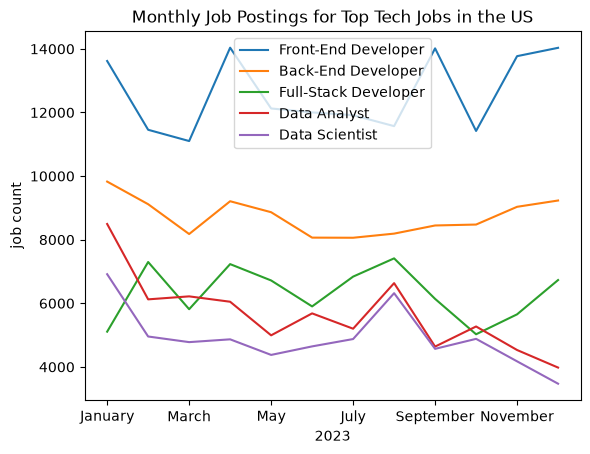

In [72]:
df_US_merged[top_5].plot(kind='line')
plt.title('Monthly Job Postings for Top Tech Jobs in the US')
plt.xlabel('2023')
plt.ylabel('job count')
plt.legend()
plt.show()

Create a new DataFrame that only gets Data Analyst jobs, creates a column for the month, and get the job postings by month.

In [73]:
# Filtter for Data Analysts
df_DA = df[df['job_title_short'] == 'Data Analyst'].copy()
#Create a column for month 
df_DA['month'] = df_DA['job_posted_date'].dt.month
#Pivot table to count job posting by month
df_DA_pivot= df_DA.pivot_table(index = 'month' , aggfunc = 'count')['job_title_short' ]
#Print the pivot table
df_DA_pivot



month
1     23585
2     16558
3     16243
4     15514
5     13423
6     16008
7     16095
8     18628
9     14969
10    16239
11    15230
12    13583
Name: job_title_short, dtype: int64

In [74]:
#Filtter for Senior Data Analysts 
df_SDA = df[df['job_title_short'] == 'Senior Data Analyst'].copy()
#Create a column for month
df_SDA['month']= df_SDA['job_posted_date'].dt.month
#Pivot table to count job postings by month
df_SDA_pivot = df_SDA.pivot_table(index= 'month', aggfunc= 'count')['job_title_short']
#Print pivot table
df_SDA_pivot

month
1     3696
2     2713
3     2454
4     2351
5     1925
6     2319
7     2380
8     2951
9     2194
10    2317
11    2117
12    1799
Name: job_title_short, dtype: int64

In [75]:
#Merge the two pivot tables
merged_DA_pivot= pd.merge(df_SDA_pivot , df_SDA_pivot, how = 'outer', left_index= True , right_index = True)
merged_DA_pivot.columns = ['DA_count' ,'SDA_count' ]
merged_DA_pivot

,DA_count,SDA_count
month,,
1,3696,3696
2,2713,2713
3,2454,2454
4,2351,2351
5,1925,1925
6,2319,2319
7,2380,2380
8,2951,2951
9,2194,2194
